# Huấn luyện bộ phân loại cử chỉ tay

**Đề tài:** AI Hand-Gesture Authenticated Smart Door Lock — hệ thống IoT 4 tầng

Notebook này huấn luyện một mạng nơ-ron nhỏ (MLP) để phân loại **7 lớp cử chỉ**
từ vector đặc trưng **42 chiều** do `common.preprocess_landmarks()` sinh ra.

**Cập nhật 31/10/2026:** mạng mới, thêm dữ liệu công khai trên GitHub (Bước 2b),
trọng số mẫu và chọn ngưỡng tin cậy bằng giả lập máy trạng thái (Bước 7b).
Bảng so sánh từng thay đổi: `docs/ket_qua_cai_tien_train.md`.

> Kết quả đang hiện trong các ô là lần chạy ngày 31/10/2026 trên một máy Linux, cùng
> TensorFlow 2.21 (vì thế đường dẫn in ra có dạng `/home/...`). Bấm **Run All** để chạy lại
> trên máy của bạn — seed cố định nên con số sẽ trùng hoặc lệch rất ít.

| Bước | Nội dung |
|---|---|
| 1 | Nạp thư viện và cấu hình |
| 2 | Đọc `model/keypoint.csv` + `model/keypoint_meta.csv` và kiểm tra dữ liệu |
| 2b | Đọc dữ liệu GitHub `model/keypoint_github.csv` — **chỉ dùng để train** |
| 3 | Chia 5 fold **theo burst** bằng `StratifiedGroupKFold` |
| 4 | Dựng mạng MLP |
| 5 | Huấn luyện trên từng fold với EarlyStopping, gom dự đoán out-of-fold |
| 6 | Đánh giá: classification report + ma trận nhầm lẫn out-of-fold |
| 7 | Độ chính xác từng lớp (trung bình ± độ lệch chuẩn qua 5 fold), cảnh báo cặp dễ nhầm — **con số báo cáo**, lưu `model/eval_metrics.json` |
| 7b | Chọn ngưỡng `min_confidence` từ xác suất out-of-fold |
| 8 | Train lại trên **toàn bộ** dữ liệu — **model triển khai** |
| 9 | Lưu model `.keras` và `.tflite`, đối chiếu hai bản |

> **Con số báo cáo và model triển khai là hai thứ khác nhau.** Mọi con số đánh giá
> (Bước 5–7) đến từ kiểm định chéo 5 fold chia theo burst. Model được lưu ra `.tflite`
> (Bước 9) là bản train lại trên toàn bộ dữ liệu ở Bước 8 — bản đó không có con số
> đánh giá riêng.

> **Chạy notebook này TRƯỚC KHI** chạy `gesture_lock.py`, vì `gesture_lock.py`
> nạp file `.tflite` do bước 9 sinh ra.
>
> Yêu cầu: đã chạy `collect_data.py` và thu **250–300 mẫu mỗi lớp**, kể cả lớp `none`.

## Bước 1 — Nạp thư viện và cấu hình

Mọi tham số (đường dẫn, danh sách lớp) đều đọc từ `config.json`, không viết cứng
trong notebook. Nhờ vậy sửa một chỗ là cả hệ thống đổi theo.

In [1]:
import csv
import hashlib
import json
import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix

# Cho phép import common.py nằm cùng thư mục vision/
VISION_DIR = Path.cwd()
if not (VISION_DIR / "common.py").exists():          # phòng khi mở notebook từ gốc dự án
    VISION_DIR = VISION_DIR / "vision"
sys.path.insert(0, str(VISION_DIR))

from common import load_config, gesture_tables, resolve_path, FEATURE_DIM

cfg = load_config(VISION_DIR / "config.json")
ID_TO_LABEL, _ = gesture_tables(cfg)
CLASS_NAMES = [ID_TO_LABEL[i] for i in sorted(ID_TO_LABEL)]
NUM_CLASSES = len(CLASS_NAMES)

CSV_PATH     = resolve_path(cfg["model"]["keypoint_csv"])
META_PATH    = resolve_path(cfg["model"]["keypoint_meta_csv"])
METRICS_PATH = resolve_path(cfg["model"]["eval_metrics_json"])
KERAS_PATH   = resolve_path(cfg["model"]["classifier_keras"])
TFLITE_PATH  = resolve_path(cfg["model"]["classifier_tflite"])
CM_PNG_PATH  = (VISION_DIR.parent / "docs" / "confusion_matrix.png").resolve()

RANDOM_STATE = 42
N_FOLD       = 5
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow :", tf.__version__)
print("So chieu dac trung :", FEATURE_DIM)
print("So lop             :", NUM_CLASSES, "->", CLASS_NAMES)
print("File du lieu       :", CSV_PATH)

# ===================================================================
#  CO TRON HaGRID VAO TAP TRAIN?  —  MAC DINH PHAI LA False
# ===================================================================
#  False (mac dinh):
#     HaGRID la TAP KIEM THU DOC LAP. Model chi hoc tu du lieu tu thu bang
#     webcam, va vision/eval_external.py do duoc dung cau hoi:
#     "model co nhan duoc ban tay cua NGUOI KHAC khong".
#
#  True:
#     HaGRID duoc noi vao tap train. KHI DO HaGRID KHONG CON LA TAP KIEM THU
#     DOC LAP NUA — con so cua eval_external.py mat y nghia, vi model da nhin
#     thay chinh du lieu do trong luc hoc.
#     Bat co nay thi PHAI ghi ro trong bao cao, va TUYET DOI khong duoc trinh
#     bay con so HaGRID nhu ket qua kiem thu doc lap.
USE_HAGRID_FOR_TRAINING = False

HAGRID_CSV = resolve_path("model/keypoint_hagrid.csv")
print("USE_HAGRID_FOR_TRAINING :", USE_HAGRID_FOR_TRAINING)

# ===================================================================
#  CAC LUA CHON HUAN LUYEN (them ngay 31/10/2026)
# ===================================================================
#  Moi lua chon duoi day da duoc thu tung cai mot, giu cai nao lam diem
#  kiem dinh cheo TREN DU LIEU TU THU tang len. Bang so sanh day du:
#  docs/ket_qua_cai_tien_train.md
#
#  USE_GITHUB_DATA : noi them du lieu landmark cong khai tren GitHub vao
#      PHAN TRAIN cua moi fold (khong bao gio vao validation). Du lieu nay
#      do NGUOI KHAC thu, nen giup model nhan duoc tay nguoi la.
#      HaGRID VAN la tap kiem thu doc lap vi khong dung de train.
#  TRONG_SO_GITHUB : tong trong so du lieu GitHub cua moi lop = he so nay x
#      so mau tu thu cua lop do. Nho hon 1 de du lieu ngoai khong lan at
#      du lieu webcam cua chinh minh.
#  TRONG_SO_NONE   : nhan trong so mau lop none. Du lieu GitHub khong co
#      lop none, nen phai do lai cho lop nay khong bi lan at.
USE_GITHUB_DATA = True
TRONG_SO_GITHUB = 0.5
TRONG_SO_NONE   = 2.0
GITHUB_CSV = resolve_path("model/keypoint_github.csv")
print("USE_GITHUB_DATA :", USE_GITHUB_DATA, "| trong so", TRONG_SO_GITHUB,
      "| none x", TRONG_SO_NONE)


TensorFlow : 2.21.0
So chieu dac trung : 42
So lop             : 7 -> ['fist', 'palm', 'victory', 'thumb_up', 'point_up', 'ok', 'none']
File du lieu       : /home/claude/w2/vision/model/keypoint.csv
USE_HAGRID_FOR_TRAINING : False
USE_GITHUB_DATA : True | trong so 0.5 | none x 2.0


### Về cờ `USE_HAGRID_FOR_TRAINING`

Cờ này nằm ở cell đầu và **mặc định là `False`**.

HaGRID được dùng làm **tập kiểm thử độc lập**: model học từ dữ liệu tự thu bằng webcam,
rồi `vision/eval_external.py` đo xem nó có nhận được bàn tay của *người khác* hay không.
Con số trên HaGRID sẽ thấp hơn tập validation tự thu — đó là kết quả đúng và trung thực,
không phải lỗi. Khoảng cách giữa hai con số chính là thứ đáng đưa vào báo cáo.

Nếu bật cờ lên `True`, HaGRID được nối vào tập train. **Khi đó HaGRID không còn là tập
kiểm thử độc lập nữa** — model đã nhìn thấy chính dữ liệu đó lúc học, nên con số của
`eval_external.py` mất ý nghĩa kiểm thử. Bật cờ thì phải ghi rõ trong báo cáo.
### Vì sao vẫn giữ HaGRID ngoài tập train

Từ 31/10 dữ liệu "người khác" để train lấy từ **GitHub** (Bước 2b), không lấy từ HaGRID.
Nhờ vậy HaGRID **vẫn là tập kiểm thử độc lập**: model chưa từng thấy ảnh nào của nó, và
con số trên HaGRID trả lời đúng câu hỏi "có nhận được tay người lạ không".


## Bước 2 — Đọc dữ liệu và kiểm tra

Định dạng `keypoint.csv`: mỗi dòng là 1 mẫu, **cột 1** là `class_id`, **42 cột sau**
là vector đặc trưng.

Bốn thứ cần kiểm tra trước khi train, vì nếu sai thì train xong mới phát hiện sẽ rất mất công:

1. **Số cột đúng 43** — sai nghĩa là khâu tiền xử lý đã đổi mà dữ liệu cũ còn lẫn vào.
2. **Không có NaN** — một dòng NaN đủ làm toàn bộ loss thành NaN.
3. **Các lớp cân bằng** — lớp nào quá ít mẫu thì model gần như không học được lớp đó.
4. **`keypoint_meta.csv` khớp từng dòng** — mỗi mẫu phải biết mình thuộc burst nào
   (`burst_id`) thì mới chia train/validation theo burst được. File này do
   `collect_data.py` ghi song song với `keypoint.csv`.

In [2]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Chua co {CSV_PATH}.\n"
        f"Hay chay thu du lieu truoc:\n"
        f'  D:\\IoT_Gesture_sequence_door_lock\\.conda\\python.exe vision\\collect_data.py'
    )

data = np.loadtxt(CSV_PATH, delimiter=",", dtype=np.float32)
if data.ndim == 1:                      # phong truong hop file chi co 1 dong
    data = data.reshape(1, -1)

X = data[:, 1:]
y = data[:, 0].astype(np.int32)

print("Kich thuoc file :", data.shape)

# --- Kiem tra 1: so cot ---
assert data.shape[1] == FEATURE_DIM + 1, (
    f"Moi dong phai co {FEATURE_DIM + 1} cot (1 nhan + {FEATURE_DIM} dac trung), "
    f"dang co {data.shape[1]}. Co the file CSV lan du lieu cu."
)

# --- Kiem tra 2: NaN ---
n_nan = int(np.isnan(X).sum())
assert n_nan == 0, f"Co {n_nan} gia tri NaN trong du lieu. Xoa cac dong hong roi chay lai."

# --- Kiem tra 4: keypoint_meta.csv khop tung dong voi keypoint.csv ---
if not META_PATH.exists():
    raise FileNotFoundError(
        f"Chua co {META_PATH}.\n"
        "File nay ghi session_id, burst_id cho tung mau; thieu no thi khong chia\n"
        "train/val theo burst duoc. collect_data.py tu ghi file nay khi thu du lieu."
    )
with open(META_PATH, newline="", encoding="utf-8") as f:
    meta_rows = list(csv.DictReader(f))
assert len(meta_rows) == len(y), (
    f"keypoint_meta.csv co {len(meta_rows)} dong du lieu, keypoint.csv co {len(y)} dong. "
    "Hai file phai khop tung dong - co the da sua tay mot file ma quen file kia."
)
groups = np.array([r["burst_id"] for r in meta_rows])
sessions = np.array([r["session_id"] for r in meta_rows])

# --- Tuy chon: noi HaGRID vao tap train (xem canh bao o cell dau) ---
if USE_HAGRID_FOR_TRAINING:
    if not HAGRID_CSV.exists():
        raise FileNotFoundError(
            f"USE_HAGRID_FOR_TRAINING=True nhung chua co {HAGRID_CSV}.\n"
            "Chay kaggle/extract_hagrid_landmarks.ipynb tren Kaggle roi tai file ve."
        )
    dh = np.loadtxt(HAGRID_CSV, delimiter=",", dtype=np.float32)
    if dh.ndim == 1:
        dh = dh.reshape(1, -1)
    assert dh.shape[1] == FEATURE_DIM + 1, (
        f"keypoint_hagrid.csv phai co {FEATURE_DIM + 1} cot, dang co {dh.shape[1]}"
    )
    n_truoc = len(y)
    X = np.vstack([X, dh[:, 1:]])
    y = np.concatenate([y, dh[:, 0].astype(np.int32)])
    # Moi dong HaGRID la mot anh doc lap -> moi dong mot nhom rieng.
    groups = np.concatenate([groups, np.array([f"hagrid_{i}" for i in range(len(dh))])])
    sessions = np.concatenate([sessions, np.full(len(dh), "hagrid")])
    print()
    print("*" * 70)
    print("*  DA TRON HaGRID VAO TAP TRAIN                                      *")
    print(f"*  {n_truoc} mau tu thu + {len(dh)} mau HaGRID = {len(y)} mau" .ljust(69) + "*")
    print("*  HaGRID KHONG con la tap kiem thu doc lap. Con so cua              *")
    print("*  eval_external.py khong con y nghia kiem thu. Ghi ro vao bao cao.  *")
    print("*" * 70)
elif HAGRID_CSV.exists():
    print(f"(Co {HAGRID_CSV.name} nhung USE_HAGRID_FOR_TRAINING=False")
    print(" -> giu lam tap kiem thu doc lap, dung cho eval_external.py)")

# --- Kiem tra 3: phan bo lop ---
print()
print(f"{'id':<4}{'lop':<12}{'so mau':>8}{'ty le':>9}{'burst':>7}{'phien':>7}")
print("-" * 48)
for cid in sorted(ID_TO_LABEL):
    m = (y == cid)
    n = int(m.sum())
    canh_bao = "  <-- qua it" if n < 100 else ""
    print(f"{cid:<4}{ID_TO_LABEL[cid]:<12}{n:>8}{n / len(y):>8.1%}"
          f"{len(set(groups[m])):>7}{len(set(sessions[m])):>7}{canh_bao}")
print("-" * 48)
print(f"{'':<16}{len(y):>8}  tong cong, {len(set(groups))} burst, {len(set(sessions))} phien")

thieu = [ID_TO_LABEL[c] for c in sorted(ID_TO_LABEL) if (y == c).sum() == 0]
if thieu:
    raise ValueError(f"Chua co mau nao cho lop: {thieu}. Phai thu du 7 lop moi train duoc.")

Kich thuoc file : (2504, 43)
(Co keypoint_hagrid.csv nhung USE_HAGRID_FOR_TRAINING=False
 -> giu lam tap kiem thu doc lap, dung cho eval_external.py)

id  lop           so mau    ty le  burst  phien
------------------------------------------------
0   fist             358   14.3%     12      1
1   palm             398   15.9%     14      1
2   victory          420   16.8%     14      1
3   thumb_up         377   15.1%     13      1
4   point_up         300   12.0%     10      1
5   ok               374   14.9%     13      1
6   none             277   11.1%     10      1
------------------------------------------------
                    2504  tong cong, 86 burst, 7 phien


## Bước 2b — Dữ liệu công khai trên GitHub (chỉ dùng để train)

`model/keypoint_github.csv` do `scripts/chuyen_du_lieu_github.py` tạo ra, gom hai bộ landmark
công khai (giấy phép Apache-2.0), cùng pipeline MediaPipe 21 điểm → dời gốc cổ tay → chia
max_abs như dự án:

| Nguồn | Lớp lấy | Ánh xạ |
|---|---|---|
| `thatsabhishek/hand-gesture-recognition-using-mediapipe` (gồm dữ liệu gốc của Kazuhito00 và kinivi) | Open, Close, Pointer, OK, Peace, Thumbs Up | palm, fist, point_up, ok, victory, thumb_up |
| `jaeeun/hand-gesture-recognition-using-mediapipe` | Open, Close, Pointer, OK, V, Thumb | như trên |

Khác biệt duy nhất đã sửa trong script: các repo đó lấy toạ độ **pixel**, dự án lấy toạ độ
**chuẩn hoá 0..1 của camera 640×480** (trục x bị nén 0.75 lần). Script nhân x với 0.75 rồi
chuẩn hoá lại — phép đổi chính xác.

**Ba quy tắc để không làm hỏng đánh giá:**

1. Dữ liệu GitHub **chỉ được nối vào phần train của mỗi fold**, không bao giờ vào validation.
   Con số báo cáo vẫn đo trên burst tự thu mà model chưa thấy.
2. Không có lớp `none` — lớp phân cách chỉ lấy từ dữ liệu tự thu.
3. Trọng số mẫu: tổng trọng số GitHub của mỗi lớp = `TRONG_SO_GITHUB` × số mẫu tự thu của lớp
   đó, để hơn 15 nghìn mẫu ngoài không lấn át 2.5 nghìn mẫu webcam của mình.

In [3]:
if USE_GITHUB_DATA:
    if not GITHUB_CSV.exists():
        raise FileNotFoundError(
            f"USE_GITHUB_DATA=True nhung chua co {GITHUB_CSV}.\n"
            "Chay: .conda\\python.exe scripts\\chuyen_du_lieu_github.py")
    dg = np.loadtxt(GITHUB_CSV, delimiter=",", dtype=np.float32)
    assert dg.shape[1] == FEATURE_DIM + 1, f"keypoint_github.csv phai co {FEATURE_DIM + 1} cot"
    X_gh = dg[:, 1:]
    y_gh = dg[:, 0].astype(np.int32)
    assert not np.isnan(X_gh).any()
    assert (y_gh != 6).all(), "Du lieu GitHub khong duoc co lop none"
else:
    X_gh = np.zeros((0, FEATURE_DIM), dtype=np.float32)
    y_gh = np.zeros(0, dtype=np.int32)

print(f"Du lieu GitHub: {len(y_gh)} mau (chi dung de train)")
for cid in sorted(ID_TO_LABEL):
    print(f"  {ID_TO_LABEL[cid]:<10}{int((y_gh == cid).sum()):>7}")


def trong_so_github(y_train_tu_thu):
    """Trong so cho tung mau GitHub: tong trong so moi lop = TRONG_SO_GITHUB x so mau
    tu thu cua lop do trong phan train hien tai."""
    w = np.zeros(len(y_gh), dtype=np.float32)
    for c in range(NUM_CLASSES):
        m = y_gh == c
        if m.any():
            w[m] = TRONG_SO_GITHUB * (y_train_tu_thu == c).sum() / m.sum()
    return w


def tap_train(X_tu_thu, y_tu_thu):
    """Ghep tap train cho 1 lan huan luyen: du lieu tu thu (+ GitHub).
    Tra ve (dac trung 42 chieu, nhan, trong so)."""
    w = np.where(y_tu_thu == 6, TRONG_SO_NONE, 1.0).astype(np.float32)
    Xa, ya, wa = X_tu_thu, y_tu_thu, w
    if USE_GITHUB_DATA:
        Xa = np.vstack([Xa, X_gh])
        ya = np.concatenate([ya, y_gh])
        wa = np.concatenate([wa, trong_so_github(y_tu_thu)])
    return Xa, ya, wa

Du lieu GitHub: 15620 mau (chi dung de train)
  fist         3555
  palm         3350
  victory      1654
  thumb_up     1736
  point_up     3307
  ok           2018
  none            0


## Bước 3 — Kiểm định chéo 5 fold, chia theo burst

Mỗi lần bấm **R** trong `collect_data.py` ghi 30 mẫu liên tiếp, cách nhau 2 khung hình —
gần như cùng một tư thế tay. Nếu chia ngẫu nhiên từng mẫu (`train_test_split`), 30 mẫu đó
bị xé ra hai phía: ở validation model gặp lại đúng tư thế nó vừa học ở train, và điểm
validation bị **thổi phồng** mà không có dấu hiệu gì báo ra ngoài.
(Phép đo cụ thể: `scripts/chan_doan_du_lieu.py`, mục 3b — cột "tính cả burst" so với "BỎ burst".)

Dùng `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`, nhóm = `burst_id`
đọc từ `keypoint_meta.csv`:

- **Group** — mọi mẫu của một burst nằm trọn trong một fold: không burst nào vừa ở
  train vừa ở validation.
- **Stratified** — tỉ lệ các lớp trong mỗi fold xấp xỉ toàn bộ dữ liệu, nên fold nào
  cũng có đủ 7 lớp. Ô dưới **assert** điều này; lớp nào có ít hơn 5 burst sẽ làm hỏng nó.
- **5 fold** — mỗi burst làm validation đúng một lần. Gom dự đoán của 5 lần đó
  (*out-of-fold*) thì **mọi** mẫu đều có một dự đoán từ một model chưa từng học burst
  của nó — ma trận nhầm lẫn dùng hết dữ liệu chứ không chỉ 20%.

Vì sao không dùng một lần chia 80/20: với chừng 90 burst, một lần chia chỉ để 2–3 burst
mỗi lớp vào validation, và độ chính xác từng lớp phụ thuộc mạnh vào việc burst nào bị
bốc trúng. 5 fold cho cả **trung bình** lẫn **độ lệch chuẩn** — thấy được con số dao
động bao nhiêu.

`random_state=42` để mỗi lần chạy lại đều ra cùng một cách chia.

**Giới hạn:** chia theo burst đo được "model có nhận ra một *lần làm cử chỉ mới* không",
nhưng các burst cùng một phiên vẫn chung ánh sáng và chỗ ngồi. Khi đã có từ 3 phiên thu
mới trở lên, chia theo `session_id` mới đo được khả năng sang *điều kiện mới*.

In [4]:
# Kiem dinh cheo 5 fold: nhom theo burst_id, phan tang theo lop.
sgkf = StratifiedGroupKFold(n_splits=N_FOLD, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(sgkf.split(X, y, groups))

# --- Kiem tra: moi fold du 7 lop o validation, khong burst nao nam o ca hai phia,
#     moi mau nam trong validation dung mot lan ---
lan_val = np.zeros(len(y), dtype=int)
for k, (tr, va) in enumerate(FOLDS):
    chung = set(groups[tr]) & set(groups[va])
    assert not chung, f"fold {k}: {len(chung)} burst nam o ca train va val"
    thieu = [ID_TO_LABEL[c] for c in sorted(ID_TO_LABEL) if not (y[va] == c).any()]
    assert not thieu, (f"fold {k}: validation thieu lop {thieu}. Lop do co qua it burst "
                       f"(can it nhat {N_FOLD}) - thu them du lieu roi chay lai.")
    lan_val[va] += 1
assert (lan_val == 1).all(), "Moi mau phai nam trong validation dung mot lan"

print(f"{N_FOLD} fold, {len(set(groups))} burst, {len(y)} mau - "
      "moi mau nam trong validation dung 1 lan, fold nao cung du 7 lop")
print()
print(f"{'fold':<6}{'val mau':>9}{'val burst':>11}   so burst validation moi lop")
print("-" * 86)
for k, (tr, va) in enumerate(FOLDS):
    moi_lop = " ".join(f"{ID_TO_LABEL[c]}:{len(set(groups[va][y[va] == c]))}"
                       for c in sorted(ID_TO_LABEL))
    print(f"{k:<6}{len(va):>9}{len(set(groups[va])):>11}   {moi_lop}")

5 fold, 86 burst, 2504 mau - moi mau nam trong validation dung 1 lan, fold nao cung du 7 lop

fold    val mau  val burst   so burst validation moi lop
--------------------------------------------------------------------------------------
0           510         17   fist:3 palm:3 victory:2 thumb_up:3 point_up:2 ok:2 none:2
1           515         18   fist:3 palm:3 victory:3 thumb_up:2 point_up:2 ok:3 none:2
2           497         17   fist:2 palm:2 victory:3 thumb_up:3 point_up:2 ok:3 none:2
3           494         17   fist:2 palm:3 victory:3 thumb_up:2 point_up:2 ok:3 none:2
4           488         17   fist:2 palm:3 victory:3 thumb_up:3 point_up:2 ok:2 none:2


## Bước 4 — Dựng mạng MLP

```
Input(42)
  -> Dense(64, relu)
  -> Dropout(0.3)
  -> Dense(32, relu)
  -> Dropout(0.2)
  -> Dense(7, softmax)
```

Mạng vẫn **nhỏ** (vài nghìn tham số, chạy dưới 1 ms mỗi khung trên CPU laptop). Lý do:

- Đầu vào đã được chuẩn hoá kỹ ở `preprocess_landmarks()` (bỏ vị trí, bỏ kích thước,
  quy tay trái về tay phải), nên bài toán còn lại khá dễ — không cần mạng lớn.
- Mạng lớn dễ **học thuộc** dữ liệu thay vì học quy luật.

**Thay đổi so với bản 26/09** (`Input(42) → Dropout(0.2) → Dense(20) → Dropout(0.4) → Dense(10)`):

- **Bỏ Dropout ở đầu vào.** Nó tắt ngẫu nhiên từng toạ độ — giống che mất một đầu ngón tay
  lúc học. Với dữ liệu hình học, cách đó làm hại nhiều hơn giúp.
- **Lớp ẩn rộng hơn.** Lớp `Dense(10)` quá hẹp cộng dropout dày làm model "rụt rè": lúc chạy
  thật độ tin cậy chỉ 0.45–0.54, phải hạ `min_confidence` xuống 0.45.

**Đã thử và bỏ: 20 đặc trưng góc ngón tay** (cos góc 15 khớp + 5 tỉ lệ khoảng cách). Trên dữ
liệu tự thu không tốt hơn (72.8% so với 74.3% khi chỉ dùng 42 toạ độ), còn trên HaGRID — tay
người lạ — lại **kém hẳn** (75.4% so với 91.3% khi đã có dữ liệu GitHub). Nên giữ 42 chiều.

**Đã thử và bỏ: augmentation** (xoay ±15°, co giãn, nhiễu nhỏ). Khi đã có dữ liệu GitHub thì
không cải thiện (80.2% có augment, 80.4% không augment) — bỏ cho notebook gọn.

Dùng `sparse_categorical_crossentropy` vì nhãn đang ở dạng số nguyên `0..6`.

In [5]:
def dung_model():
    """Dung va compile mot MLP moi tu dau. Moi fold o Buoc 5 va ban trien khai
    o Buoc 8 deu goi ham nay: CUNG kien truc, CUNG seed."""
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(FEATURE_DIM,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    m.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        weighted_metrics=["accuracy"],
    )
    return m


dung_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,063 (19.78 KB)

 Trainable params: 5,063 (19.78 KB)

 Non-trainable params: 0 (0.00 B)

## Bước 5 — Huấn luyện trên từng fold

Mỗi fold: dựng mạng mới bằng `dung_model()`, train trên 4/5 số burst **tự thu** cộng toàn
bộ dữ liệu GitHub (nếu bật) — ghép bởi hàm `tap_train()` ở Bước 2b.
Validation **chỉ** là 1/5 burst tự thu còn lại, không trộn gì.
`EarlyStopping(patience=20)` theo dõi `val_loss` của fold còn lại: qua **20 epoch liên
tiếp** mà validation không khá lên thì dừng, và `restore_best_weights=True` lấy lại trọng
số của epoch tốt nhất. Đặt `epochs=1000` cũng không sao — thực tế sẽ tự dừng sớm hơn nhiều.

Dự đoán trên fold validation được ghi vào `oof_pred`. Sau 5 fold, mỗi mẫu có **đúng một**
dự đoán, đến từ một model chưa từng học burst của nó.

Số epoch tốt nhất của 5 fold được ghi lại. Bản triển khai ở Bước 8 train trên toàn bộ dữ
liệu, không còn validation để dừng sớm, nên chạy đúng **trung vị** của 5 số đó.

**Lưu ý trung thực:** EarlyStopping chọn epoch dựa trên chính fold validation, nên con số
của fold đó lạc quan hơn một chút so với dữ liệu hoàn toàn mới. Mức lệch này nhỏ so với
rò rỉ burst đã sửa, nhưng vẫn phải nêu trong báo cáo.

In [6]:
oof_pred = np.full(len(y), -1, dtype=np.int32)       # du doan out-of-fold cho moi mau
oof_prob = np.zeros((len(y), NUM_CLASSES), dtype=np.float32)  # xac suat out-of-fold (Buoc 7b)
HISTORIES, BEST_EPOCHS, ACC_FOLD = [], [], []
RECALL_FOLD = np.zeros((N_FOLD, NUM_CLASSES))        # do chinh xac tung lop, moi fold 1 hang
for k, (tr, va) in enumerate(FOLDS):
    X_tr, y_tr, w_tr = tap_train(X[tr], y[tr])        # chi phan TRAIN moi duoc ghep them
    X_va = X[va]                                      # validation: du lieu tu thu nguyen ban
    model = dung_model()
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=0,
    )
    h = model.fit(
        X_tr, y_tr,
        sample_weight=w_tr,
        validation_data=(X_va, y[va]),
        epochs=1000,
        batch_size=256,
        callbacks=[early_stop],
        verbose=0,
    )
    prob = model.predict(X_va, verbose=0)
    pred = np.argmax(prob, axis=1)
    oof_pred[va] = pred
    oof_prob[va] = prob

    cm_k = confusion_matrix(y[va], pred, labels=list(range(NUM_CLASSES)))
    RECALL_FOLD[k] = np.diag(cm_k) / cm_k.sum(axis=1)   # fold nao cung du 7 lop (Buoc 3)
    ACC_FOLD.append(float((pred == y[va]).mean()))
    # restore_best_weights lay trong so cua epoch co val_loss nho nhat.
    BEST_EPOCHS.append(int(np.argmin(h.history["val_loss"])) + 1)
    HISTORIES.append(h.history)
    print(f"fold {k}: train {len(y_tr):>6} mau, {len(h.history['loss']):>4} epoch, "
          f"tot nhat {BEST_EPOCHS[-1]:>4}, val accuracy {ACC_FOLD[-1]:.1%}")

assert (oof_pred >= 0).all(), "Con mau chua co du doan out-of-fold"
SO_EPOCH_TOT_NHAT = int(np.median(BEST_EPOCHS))
print()
print("Epoch tot nhat 5 fold:", BEST_EPOCHS, "-> trung vi", SO_EPOCH_TOT_NHAT, "(dung o Buoc 8)")

fold 0: train  17614 mau,   42 epoch, tot nhat   22, val accuracy 79.8%


fold 1: train  17609 mau,   76 epoch, tot nhat   56, val accuracy 79.8%


fold 2: train  17627 mau,   38 epoch, tot nhat   18, val accuracy 72.2%


fold 3: train  17630 mau,   64 epoch, tot nhat   44, val accuracy 79.4%


fold 4: train  17636 mau,   58 epoch, tot nhat   38, val accuracy 71.5%

Epoch tot nhat 5 fold: [22, 56, 18, 44, 38] -> trung vi 38 (dung o Buoc 8)


### Đường học của 5 fold

Hai đường `train` và `validation` bám sát nhau là tốt. Nếu đường train tiếp tục giảm
mà đường validation đi ngang rồi ngóc lên, đó là dấu hiệu **học thuộc** — cần thu thêm
dữ liệu đa dạng hơn (đổi góc tay, đổi ánh sáng, đổi khoảng cách).

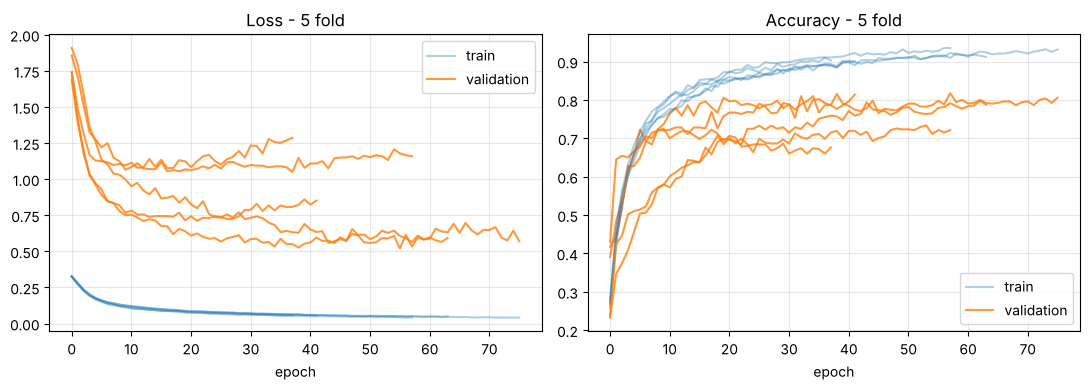

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for k, hist in enumerate(HISTORIES):
    nhan_tr = "train" if k == 0 else None
    nhan_va = "validation" if k == 0 else None
    axes[0].plot(hist["loss"], color="C0", alpha=0.35, label=nhan_tr)
    axes[0].plot(hist["val_loss"], color="C1", alpha=0.8, label=nhan_va)
    axes[1].plot(hist["accuracy"], color="C0", alpha=0.35, label=nhan_tr)
    axes[1].plot(hist["val_accuracy"], color="C1", alpha=0.8, label=nhan_va)

axes[0].set_title(f"Loss - {N_FOLD} fold")
axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set_title(f"Accuracy - {N_FOLD} fold")
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

## Bước 6 — Đánh giá out-of-fold

Mọi con số dưới đây tính trên dự đoán out-of-fold của **toàn bộ** dữ liệu: mỗi mẫu
được chấm bởi model của fold không chứa burst của nó.

`classification_report` cho 3 con số mỗi lớp:

- **precision** — trong những lần model kêu là lớp X, bao nhiêu phần trăm đúng.
  Thấp nghĩa là model hay **báo nhầm** thành lớp X.
- **recall** — trong những mẫu thật sự là lớp X, model bắt được bao nhiêu phần trăm.
  Thấp nghĩa là model hay **bỏ sót** lớp X.
- **f1-score** — trung bình điều hoà của hai cái trên.

Với bài khoá cửa này, **precision của các lớp cử chỉ quan trọng hơn recall**: báo nhầm
một cử chỉ sẽ làm sai mã và bị khoá, còn bỏ sót thì người dùng chỉ cần giữ tay lâu hơn.

In [8]:
print(classification_report(
    y, oof_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

        fist      0.726     0.860     0.788       358
        palm      0.899     0.899     0.899       398
     victory      0.746     0.581     0.653       420
    thumb_up      0.842     0.833     0.837       377
    point_up      0.690     0.683     0.687       300
          ok      0.913     0.789     0.846       374
        none      0.536     0.700     0.607       277

    accuracy                          0.766      2504
   macro avg      0.765     0.764     0.760      2504
weighted avg      0.777     0.766     0.767      2504



### Ma trận nhầm lẫn gộp out-of-fold

Gộp dự đoán của 5 fold nên ma trận đếm trên **toàn bộ** mẫu, không chỉ một phần validation.

Đọc theo **hàng**: hàng `i` là các mẫu thật sự thuộc lớp `i`, cột `j` là số mẫu bị
model đoán thành lớp `j`. Đường chéo là đoán đúng. Ô sáng nằm ngoài đường chéo chính
là **cặp cử chỉ bị nhầm** — đó là chỗ cần thu thêm dữ liệu.

Hình được lưu ra `docs/confusion_matrix.png` để đưa vào báo cáo.

Da luu: /home/claude/w2/docs/confusion_matrix.png


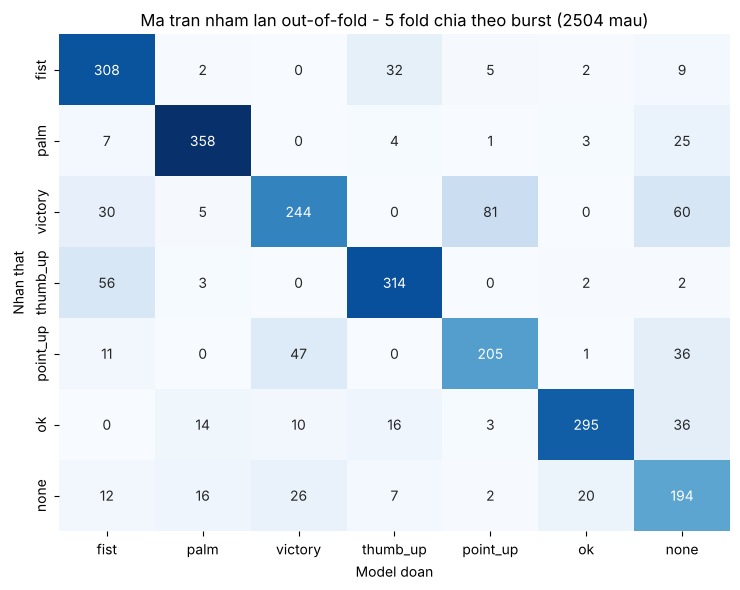

In [9]:
cm = confusion_matrix(y, oof_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(7.5, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
)
plt.xlabel("Model doan")
plt.ylabel("Nhan that")
plt.title(f"Ma tran nham lan out-of-fold - {N_FOLD} fold chia theo burst ({len(y)} mau)")
plt.tight_layout()

CM_PNG_PATH.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(CM_PNG_PATH, dpi=150)
print("Da luu:", CM_PNG_PATH)
plt.show()

## Bước 7 — Độ chính xác từng lớp và cảnh báo cặp dễ nhầm

> **Đây là con số đưa vào báo cáo** — trung bình ± độ lệch chuẩn qua 5 fold chia theo
> burst, cùng ma trận nhầm lẫn out-of-fold. Không dùng con số của bất kỳ lần chia ngẫu
> nhiên nào trước đây.

Ô cuối cùng trả lời đúng một câu hỏi: **cử chỉ nào chưa dùng được?**

Ngưỡng cảnh báo là **10%** — nghĩa là nếu cứ 10 lần làm cử chỉ A thì có hơn 1 lần
model đọc thành B, cặp (A, B) bị coi là chưa đạt.

Với hệ khoá cửa cần 3 cử chỉ liên tiếp, sai số dồn lại rất nhanh: mỗi cử chỉ đúng 90%
thì cả chuỗi chỉ còn `0.9³ ≈ 73%` — cứ 4 lần mở cửa là hỏng 1 lần.

**Cách xử lý khi có cảnh báo:**
1. Thu thêm 100–150 mẫu cho **cả hai** lớp trong cặp bị nhầm, cố ý làm ở nhiều góc
   tay và khoảng cách khác nhau, rồi train lại.
2. Nếu vẫn nhầm, **đổi mật mã** sang cặp cử chỉ khác — cách này nhanh và chắc ăn hơn.

In [10]:
NGUONG_CANH_BAO = 0.10
TB, DLC = RECALL_FOLD.mean(axis=0), RECALL_FOLD.std(axis=0, ddof=1)
ACC_TB, ACC_DLC = float(np.mean(ACC_FOLD)), float(np.std(ACC_FOLD, ddof=1))
ACC_OOF = float((oof_pred == y).mean())

print(f"DO CHINH XAC TUNG LOP - {N_FOLD} fold chia theo burst (StratifiedGroupKFold)")
print("-" * 66)
print(f"{'lop':<12}{'so mau':>8}{'trung binh':>12}{'do lech chuan':>16}{'out-of-fold':>14}")
print("-" * 66)
for i, ten in enumerate(CLASS_NAMES):
    tong = int(cm[i].sum())
    danh_dau = "" if TB[i] >= 0.95 else ("  <-- yeu" if TB[i] >= 0.85 else "  <-- RAT YEU")
    print(f"{ten:<12}{tong:>8}{TB[i]:>12.1%}{'± ' + format(DLC[i], '.1%'):>16}"
          f"{cm[i, i] / tong:>14.1%}{danh_dau}")
print("-" * 66)
print(f"{'tong the':<12}{len(y):>8}{ACC_TB:>12.1%}{'± ' + format(ACC_DLC, '.1%'):>16}{ACC_OOF:>14.1%}")
print("(do lech chuan tinh voi ddof=1 tren 5 fold; out-of-fold tinh tren ma tran gop)")

# --- Cac cap lop nham nhau qua nguong ---
canh_bao = []
for i in range(NUM_CLASSES):
    tong = int(cm[i].sum())
    if tong == 0:
        continue
    for j in range(NUM_CLASSES):
        if i == j:
            continue
        ty_le = cm[i, j] / tong
        if ty_le > NGUONG_CANH_BAO:
            canh_bao.append((ty_le, CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), tong))

print()
if not canh_bao:
    print(f"OK - khong co cap lop nao nham nhau qua {NGUONG_CANH_BAO:.0%}.")
    print("Model du tot de chay gesture_lock.py.")
else:
    print(f"CANH BAO - co {len(canh_bao)} cap lop nham nhau tren {NGUONG_CANH_BAO:.0%}:")
    print()
    for ty_le, that, doan, so_lan, tong in sorted(canh_bao, reverse=True):
        print(f"  '{that}' bi doan thanh '{doan}': {so_lan}/{tong} = {ty_le:.1%}")
    print()
    print("Xu ly: thu them du lieu cho CA HAI lop trong moi cap roi train lai,")
    print("hoac doi mat ma sang cu chi khac (sua secret.default_code trong config.json")
    print("va bien MA_MAC_DINH trong middleware/flows.json).")

# --- Nhac rieng ve cac cu chi dang nam trong mat ma ---
ma = cfg["secret"]["default_code"]
hex_to_label = {g["hex"]: g["label"] for g in cfg["gestures"] if g["hex"]}
trong_ma = [hex_to_label.get(ma[k:k + 2]) for k in range(0, len(ma), 2)]
print()
print(f"Mat ma hien tai '{ma}' dung cac cu chi: {trong_ma}")
lien_quan = [c for c in canh_bao if c[1] in trong_ma or c[2] in trong_ma]
if lien_quan:
    print("NGHIEM TRONG: cac cu chi trong mat ma dang nam trong cap bi nham.")
else:
    print("Cac cu chi trong mat ma khong nam trong cap nham nao.")

DO CHINH XAC TUNG LOP - 5 fold chia theo burst (StratifiedGroupKFold)
------------------------------------------------------------------
lop           so mau  trung binh   do lech chuan   out-of-fold
------------------------------------------------------------------
fist             358       86.0%         ± 10.1%         86.0%  <-- yeu
palm             398       88.9%         ± 14.6%         89.9%  <-- yeu
victory          420       55.2%         ± 28.6%         58.1%  <-- RAT YEU
thumb_up         377       85.5%         ± 16.8%         83.3%  <-- yeu
point_up         300       68.3%          ± 8.7%         68.3%  <-- RAT YEU
ok               374       79.3%         ± 14.8%         78.9%  <-- RAT YEU
none             277       69.8%         ± 20.2%         70.0%  <-- RAT YEU
------------------------------------------------------------------
tong the        2504       76.5%          ± 4.3%         76.6%
(do lech chuan tinh voi ddof=1 tren 5 fold; out-of-fold tinh tren ma tran gop)

CAN

### Lưu số liệu đánh giá ra `model/eval_metrics.json`

`vision/eval_external.py` đọc file này cho phía "validation tự thu" khi so với HaGRID —
nó **không** tự chia lại dữ liệu nữa. File ghi kèm md5 của `keypoint.csv` để phát hiện
số liệu đã cũ (dữ liệu đổi sau lần đánh giá).

In [11]:
with open(CSV_PATH, "rb") as f:
    md5_du_lieu = hashlib.md5(f.read()).hexdigest()

metrics = {
    "phuong_phap": "StratifiedGroupKFold",
    "n_splits": N_FOLD,
    "shuffle": True,
    "random_state": RANDOM_STATE,
    "nhom": "burst_id",
    "std_ddof": 1,
    "thoi_diem": datetime.now().isoformat(timespec="seconds"),
    "keypoint_csv_md5": md5_du_lieu,
    "use_hagrid_for_training": USE_HAGRID_FOR_TRAINING,
    "use_github_data": USE_GITHUB_DATA,
    "so_mau": int(len(y)),
    "so_burst": int(len(set(groups))),
    "so_phien": int(len(set(sessions))),
    "lop": CLASS_NAMES,
    "do_chinh_xac_tung_lop": {
        ten: {
            "mean": float(TB[i]),
            "std": float(DLC[i]),
            "oof": float(cm[i, i] / cm[i].sum()),
            "so_mau": int(cm[i].sum()),
        }
        for i, ten in enumerate(CLASS_NAMES)
    },
    "tong_the": {"mean": ACC_TB, "std": ACC_DLC, "oof": ACC_OOF},
    "do_chinh_xac_tung_fold": ACC_FOLD,
    "so_epoch_tot_nhat_moi_fold": BEST_EPOCHS,
    "ma_tran_nham_lan_oof": {"hang": "nhan that", "cot": "model doan", "gia_tri": cm.tolist()},
    "ghi_chu": ("So lieu cua kiem dinh cheo 5 fold. Model trien khai (.tflite) la ban train "
                "lai tren toan bo du lieu o Buoc 8, khong co so lieu danh gia rieng."),
}
METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)
METRICS_PATH.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print("Da luu:", METRICS_PATH)

Da luu: /home/claude/w2/vision/model/eval_metrics.json


## Bước 7b — Chọn ngưỡng tin cậy `min_confidence` có căn cứ

Trước đây ngưỡng được **đoán** (0.70), rồi phải hạ tay xuống 0.45 khi model không đạt. Ô dưới
chọn ngưỡng từ chính xác suất out-of-fold, ở **hai mức**:

1. **Mức khung hình** — với mỗi ngưỡng `t`: giữ bao nhiêu % khung, và trong số khung được giữ
   thì đúng bao nhiêu %.
2. **Mức cử chỉ (giả lập máy trạng thái)** — đây là mức quyết định. `gesture_lock.py` chỉ chấp
   nhận một cử chỉ khi có **15 khung liên tiếp** cùng nhãn và vượt ngưỡng. Mỗi burst ghi 30 mẫu
   cách nhau 2 khung, nên 15 khung ≈ **8 mẫu liên tiếp** của burst. Chạy đúng luật đó trên dự đoán
   out-of-fold của từng burst, đếm: chấp nhận **đúng**, chấp nhận **sai**, hay **chưa chấp nhận**
   (người dùng chỉ cần giữ tay lâu hơn — không gây sai mã). Với burst `none`: có bị đọc nhầm thành
   cử chỉ không.

**Luật chọn:** ngưỡng **nhỏ nhất** sao cho số burst cử chỉ bị chấp nhận **sai ≤ 3%**. Nhỏ nhất để
người dùng ít phải giữ tay lâu; ≤ 3% vì một cử chỉ sai làm hỏng cả mã và tốn một lần thử.

Ngưỡng ghi vào `eval_metrics.json` (`nguong_de_xuat`) — sửa tay vào
`config.json → thresholds.min_confidence`.

In [12]:
mx = oof_prob.max(axis=1)
dung = oof_pred == y

# --- 1. Muc khung hinh ---
print("MUC KHUNG HINH")
print(f"{'nguong':>7}{'giu lai':>10}{'dung trong so giu':>20}")
for t in [0.45, 0.5, 0.6, 0.7, 0.8, 0.9]:
    giu = mx >= t
    print(f"{t:>7.2f}{giu.mean():>10.1%}{dung[giu].mean():>20.1%}")

# --- 2. Muc cu chi: gia lap luat 15 khung on dinh tren tung burst ---
SO_MAU_ON_DINH = 8          # 15 khung / burst lay mau cach 2 khung


def gia_lap_burst(t):
    # Tra ve so burst: chap nhan dung / sai / chua chap nhan / none bi doc nham
    kq = {"dung": 0, "sai": 0, "chua": 0, "none_nham": 0}
    for b in dict.fromkeys(groups):                 # giu thu tu ghi
        idx = np.where(groups == b)[0]
        nhan_that = y[idx[0]]
        chap_nhan, chuoi, truoc = None, 0, None
        for i in idx:
            nhan = oof_pred[i] if mx[i] >= t else -1
            chuoi = chuoi + 1 if (nhan != -1 and nhan == truoc) else (1 if nhan != -1 else 0)
            truoc = nhan
            if nhan not in (-1, 6) and chuoi >= SO_MAU_ON_DINH:
                chap_nhan = nhan
                break
        if nhan_that == 6:
            kq["none_nham"] += chap_nhan is not None
        elif chap_nhan is None:
            kq["chua"] += 1
        else:
            kq["dung" if chap_nhan == nhan_that else "sai"] += 1
    return kq


n_cc = len({b for b in groups if y[groups == b][0] != 6})
n_none = len({b for b in groups if y[groups == b][0] == 6})
print()
print(f"MUC CU CHI - gia lap tren {n_cc} burst cu chi va {n_none} burst none")
print(f"{'nguong':>7}{'dung':>8}{'SAI':>8}{'chua nhan':>11}{'none bi doc nham':>19}")
BANG_NGUONG = {}
NGUONG_DE_XUAT = None
for t in [0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]:
    kq = gia_lap_burst(t)
    BANG_NGUONG[f"{t:.2f}"] = kq
    print(f"{t:>7.2f}{kq['dung']:>8}{kq['sai']:>8}{kq['chua']:>11}{kq['none_nham']:>12} / {n_none}")
    if NGUONG_DE_XUAT is None and kq["sai"] <= 0.03 * n_cc:
        NGUONG_DE_XUAT = round(float(t), 2)

print()
if NGUONG_DE_XUAT is None:
    print("Khong nguong nao giu duoc ty le chap nhan sai <= 3% - can them du lieu.")
else:
    kq = BANG_NGUONG[f"{NGUONG_DE_XUAT:.2f}"]
    print(f"NGUONG DE XUAT: min_confidence = {NGUONG_DE_XUAT}")
    print(f"  -> {kq['dung']}/{n_cc} burst chap nhan dung, {kq['sai']} sai, {kq['chua']} chua nhan")
    print(f"  -> khi da chap nhan thi dung {kq['dung'] / max(kq['dung'] + kq['sai'], 1):.1%}")
    print("Sua tay vao vision/config.json -> thresholds.min_confidence")
print(f"Trung vi do tin cay tren cac du doan DUNG: {np.median(mx[dung]):.2f}")

metrics["nguong_de_xuat"] = NGUONG_DE_XUAT
metrics["gia_lap_may_trang_thai"] = {"so_mau_on_dinh": SO_MAU_ON_DINH, "so_burst_cu_chi": n_cc,
                                     "so_burst_none": n_none, "theo_nguong": BANG_NGUONG}
metrics["trung_vi_do_tin_cay_dung"] = float(np.median(mx[dung]))
metrics["huan_luyen"] = {
    "use_github_data": USE_GITHUB_DATA, "so_mau_github": int(len(y_gh)),
    "trong_so_github": TRONG_SO_GITHUB, "trong_so_none": TRONG_SO_NONE,
    "dau_vao_model": FEATURE_DIM,
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print("Da cap nhat:", METRICS_PATH)

MUC KHUNG HINH
 nguong   giu lai   dung trong so giu
   0.45     95.6%               78.9%
   0.50     92.6%               80.0%
   0.60     85.3%               82.6%
   0.70     76.3%               85.5%
   0.80     62.9%               89.3%
   0.90     47.0%               91.7%



MUC CU CHI - gia lap tren 76 burst cu chi va 10 burst none
 nguong    dung     SAI  chua nhan   none bi doc nham
   0.45      63       6          7           2 / 10
   0.50      63       6          7           2 / 10
   0.55      63       5          8           2 / 10
   0.60      62       5          9           2 / 10
   0.65      60       5         11           2 / 10
   0.70      55       5         16           2 / 10
   0.75      54       4         18           2 / 10
   0.80      52       2         22           1 / 10
   0.85      47       2         27           1 / 10
   0.90      41       2         33           1 / 10

NGUONG DE XUAT: min_confidence = 0.8
  -> 52/76 burst chap nhan dung, 2 sai, 22 chua nhan
  -> khi da chap nhan thi dung 96.3%
Sua tay vao vision/config.json -> thresholds.min_confidence
Trung vi do tin cay tren cac du doan DUNG: 0.93
Da cap nhat: /home/claude/w2/vision/model/eval_metrics.json


## Bước 8 — Train lại trên toàn bộ dữ liệu (model triển khai)

> **Con số báo cáo là của kiểm định chéo 5 fold ở Bước 3–7. Model triển khai là bản train lại
> trên toàn bộ dữ liệu ở bước này.** Hai thứ này khác nhau và phải ghi rõ như vậy trong báo cáo.

Mỗi model ở Bước 5 chỉ học 4/5 số burst — phần còn lại là những tư thế tay mà model
chạy thật nên được học. Vì vậy sau khi đã đo xong, dựng một mạng mới bằng `dung_model()`
(cùng kiến trúc, cùng seed) và train trên **100% dữ liệu tự thu** (cộng GitHub giống hệt
lúc đánh giá), đúng `SO_EPOCH_TOT_NHAT` epoch
— trung vị số epoch tốt nhất của 5 fold ở Bước 5.

Bản này **không có con số đánh giá riêng**: không còn mẫu nào nó chưa thấy. Không lấy độ
chính xác trên chính dữ liệu train của nó đưa vào báo cáo. Nó được kiểm bằng HaGRID
(`vision/eval_external.py`) và bằng phiên chạy thật (`scripts/dem_10_lan.py`).

In [13]:
X_all, y_all, w_all = tap_train(X, y)
model_trien_khai = dung_model()
model_trien_khai.fit(
    X_all, y_all,
    sample_weight=w_all,
    epochs=SO_EPOCH_TOT_NHAT,
    batch_size=256,
    verbose=0,
)
print(f"Da train ban trien khai tren TOAN BO {len(y)} mau tu thu "
      f"(tong {len(y_all)} mau sau khi ghep GitHub), {SO_EPOCH_TOT_NHAT} epoch.")
print("Con so bao cao: lay o Buoc 7 / eval_metrics.json (5 fold chia theo burst),")
print("KHONG lay tu model nay.")

Da train ban trien khai tren TOAN BO 2504 mau tu thu (tong 18124 mau sau khi ghep GitHub), 38 epoch.
Con so bao cao: lay o Buoc 7 / eval_metrics.json (5 fold chia theo burst),
KHONG lay tu model nay.


## Bước 9 — Lưu model triển khai

Lưu `model_trien_khai` (bản train toàn bộ ở Bước 8) ra **hai** định dạng:

- **`.keras`** — bản gốc đầy đủ, để sau này train tiếp hoặc phân tích.
- **`.tflite`** — bản rút gọn, đây mới là bản mà `gesture_lock.py` nạp lúc chạy thật.
  TFLite khởi động nhanh hơn và nhẹ hơn nhiều so với nạp cả TensorFlow.

Ô cuối **đối chiếu hai model trên cùng dữ liệu**. Bước này nhìn thừa nhưng rất cần:
nếu chuyển đổi TFLite hỏng, model vẫn chạy và vẫn trả về số, chỉ là trả về **sai** —
lúc đó rất khó lần ra vì `gesture_lock.py` sẽ chỉ đơn giản là đoán lung tung.

In [14]:
KERAS_PATH.parent.mkdir(parents=True, exist_ok=True)
model_trien_khai.save(KERAS_PATH)
print("Da luu Keras :", KERAS_PATH, f"({KERAS_PATH.stat().st_size / 1024:.0f} KB)")

# Keras 3 khuyen dung duong export -> SavedModel -> TFLite.
# Van thu from_keras_model truoc vi no gon hon, hong thi quay ve cach kia.
try:
    converter = tf.lite.TFLiteConverter.from_keras_model(model_trien_khai)
    tflite_bytes = converter.convert()
except Exception as e:
    print("from_keras_model khong dung duoc:", type(e).__name__, "- chuyen sang SavedModel")
    import tempfile
    with tempfile.TemporaryDirectory() as tmp:
        model_trien_khai.export(tmp)
        converter = tf.lite.TFLiteConverter.from_saved_model(tmp)
        tflite_bytes = converter.convert()

TFLITE_PATH.write_bytes(tflite_bytes)
print("Da luu TFLite:", TFLITE_PATH, f"({len(tflite_bytes) / 1024:.0f} KB)")

Da luu Keras : /home/claude/w2/vision/model/gesture_classifier.keras (89 KB)


INFO:tensorflow:Assets written to: /tmp/tmpg9i1njo1/assets


Saved artifact at '/tmp/tmpg9i1njo1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 42), dtype=tf.float32, name='keras_tensor_36')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  140313790097040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140313790096464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140313790103376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140313790096272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140313790103184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140313790094736: TensorSpec(shape=(), dtype=tf.resource, name=None)


Da luu TFLite: /home/claude/w2/vision/model/gesture_classifier.tflite (22 KB)


In [15]:
# Doi chieu TFLite voi ban Keras TRIEN KHAI tren toan bo du lieu.
# (Khong so voi oof_pred o Buoc 5 - do la du doan cua 5 model danh gia, khong phai ban duoc luu.)
keras_pred = np.argmax(model_trien_khai.predict(X, verbose=0), axis=1)

interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

tflite_pred = []
for row in X:
    interpreter.set_tensor(inp["index"], row.reshape(1, -1).astype(np.float32))
    interpreter.invoke()
    tflite_pred.append(int(np.argmax(interpreter.get_tensor(out["index"])[0])))
tflite_pred = np.array(tflite_pred)

khop = float((tflite_pred == keras_pred).mean())
print(f"Ty le TFLite trung khop voi Keras trien khai: {khop:.4%} (tren {len(X)} mau)")
if khop < 0.999:
    print("CANH BAO: hai model lech nhau. KHONG dung file .tflite nay, kiem tra lai buoc chuyen doi.")
else:
    print("OK - file .tflite dung duoc cho gesture_lock.py")

Ty le TFLite trung khop voi Keras trien khai: 100.0000% (tren 2504 mau)
OK - file .tflite dung duoc cho gesture_lock.py
